<a href="https://colab.research.google.com/github/2007Mateo/Aprendizaje_Autom-tico_Inicial_GV/blob/main/06-SVM_Resuelto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Máquinas de soporte vectorial
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; Periodo 2026-2
            </font></p>
        </td>  
    </tr>
</table>

---
## Introducción
Aplicamos SVM a los datos reales de productividad del departamento de costura (sewing). El objetivo es clasificar si un equipo cumple o no su meta de productividad. Se emplea el mismo procedimiento del cuaderno de clase.

Los paquetes necesarios son:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.svm import SVC

---
## Ejemplo práctico
### Preprocesamiento de datos
Primero leemos los datos y seleccionamos las columnas de interés.

In [2]:
# Leer el CSV directamente desde GitHub
url = "https://raw.githubusercontent.com/2007Mateo/Aprendizaje_Autom-tico_Inicial_GV/main/Dep2.csv"
data = pd.read_csv(url, sep=";")
data = data.dropna(how="all")
data = data[data["department"] == "sewing"].copy().reset_index(drop=True)

numeric_cols = ["targeted_productivity", "smv", "over_time", "no_of_workers"]
# 1: cumple la meta; 0: no cumple
# La productividad real solo se utiliza para construir la etiqueta.
data = data.dropna(subset=numeric_cols + ["actual_productivity"])
data["cumple_meta"] = (data["actual_productivity"] >= data["targeted_productivity"]).astype(int)
print("Filas del departamento sewing:", len(data))
display(data[numeric_cols + ["cumple_meta"]].head())

Filas del departamento sewing: 691


,targeted_productivity,smv,over_time,no_of_workers,cumple_meta
0,0.8,26.16,7080,59.0,1
1,0.8,11.41,3660,30.5,1
2,0.8,11.41,3660,30.5,1
3,0.8,25.90,1920,56.0,1
4,0.8,25.90,6720,56.0,1


Revisamos los datos y la distribución de la etiqueta. No incluimos `incentive` porque puede depender del resultado de productividad, ni `actual_productivity` porque revela la respuesta.

In [3]:
display(data[numeric_cols].describe().round(2))
print("Distribución de la etiqueta (0: no cumple, 1: cumple):")
print(data["cumple_meta"].value_counts())

,targeted_productivity,smv,over_time,no_of_workers
count,691.00,691.00,691.00,691.00
mean,0.72,23.25,6508.21,52.45
std,0.10,6.98,2864.51,9.42
min,0.07,10.05,0.00,26.00
25%,0.70,18.79,4560.00,52.00
50%,0.75,22.52,6840.00,57.00
75%,0.80,28.08,7200.00,58.00
max,0.80,54.56,25920.00,89.00


Distribución de la etiqueta (0: no cumple, 1: cumple):
cumple_meta
1    548
0    143
Name: count, dtype: int64


Reservamos prueba y validación antes de escalar; el escalador se ajusta solo con entrenamiento.

In [4]:
# Reservar prueba antes de ajustar cualquier transformación
X = data[numeric_cols]
y = data['cumple_meta']  # 0: no cumple; 1: cumple
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval
)

# Ajustar el escalado solo con entrenamiento; transformar validación
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)


---
## Ejemplo: regiones de decisión
Para dibujar las regiones como en el cuaderno de clase, utilizamos dos variables reales (`smv` y `over_time`). Estos modelos de dos variables son solo para visualizar; el modelo final utiliza las cuatro variables.

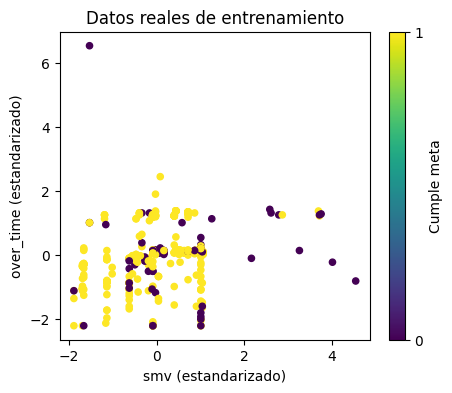

In [5]:
# Elegir dos variables de las cuatro ya estandarizadas
X_train_2d = X_train_scaled[:, [1, 2]]
X_val_2d = X_val_scaled[:, [1, 2]]

plt.figure(figsize=(5, 4))
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, s=20, cmap="viridis")
plt.xlabel("smv (estandarizado)")
plt.ylabel("over_time (estandarizado)")
plt.title("Datos reales de entrenamiento")
plt.colorbar(ticks=[0, 1], label="Cumple meta")
plt.show()

### Kernel lineal, RBF y polinomial
Entrenamos cada kernel con las mismas particiones y mostramos la región de decisión y los vectores de soporte (círculos negros).

{'kernel': 'linear'} Exactitud de validación: 0.79


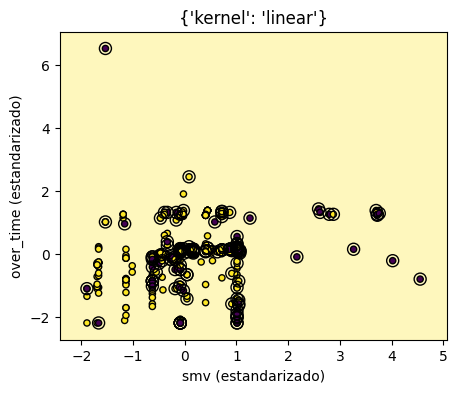

{'kernel': 'rbf'} Exactitud de validación: 0.812


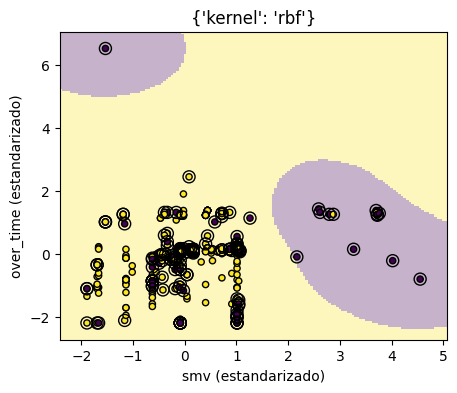

{'kernel': 'poly', 'degree': 2} Exactitud de validación: 0.79


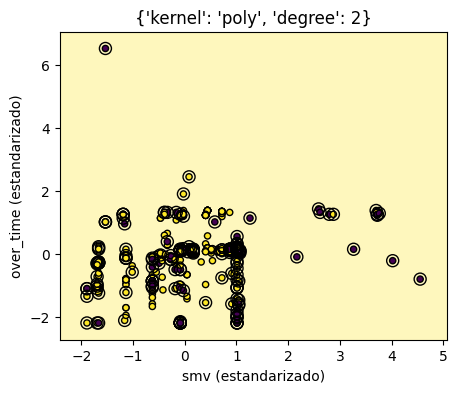

{'kernel': 'poly', 'degree': 3} Exactitud de validación: 0.804


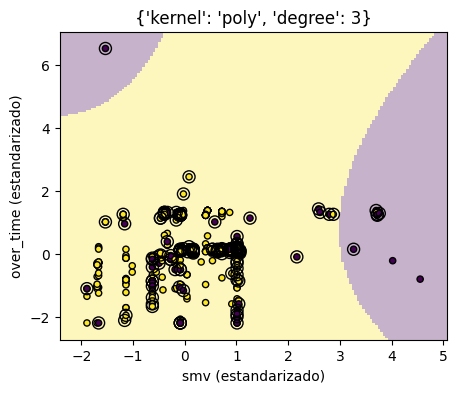

In [6]:
# Malla para las regiones de decisión
xx, yy = np.meshgrid(
    np.linspace(X_train_2d[:, 0].min()-0.5, X_train_2d[:, 0].max()+0.5, 150),
    np.linspace(X_train_2d[:, 1].min()-0.5, X_train_2d[:, 1].max()+0.5, 150)
)

for params in [{'kernel': 'linear'}, {'kernel': 'rbf'},
               {'kernel': 'poly', 'degree': 2}, {'kernel': 'poly', 'degree': 3}]:
    modelo_2d = SVC(**params)
    modelo_2d.fit(X_train_2d, y_train)
    y_pred = modelo_2d.predict(X_val_2d)
    print(params, "Exactitud de validación:", round(accuracy_score(y_val, y_pred), 3))

    Z = modelo_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(5, 4))
    plt.pcolormesh(xx, yy, Z, cmap="viridis", vmin=0, vmax=1, alpha=0.3, shading="auto")
    plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train,
                cmap="viridis", vmin=0, vmax=1, edgecolor="k", s=20)
    sv = modelo_2d.support_vectors_
    plt.scatter(sv[:, 0], sv[:, 1], s=75, facecolors="none", edgecolors="k")
    plt.xlabel("smv (estandarizado)")
    plt.ylabel("over_time (estandarizado)")
    plt.title(str(params))
    plt.show()

---
### Selección del kernel y ajuste de C y gamma
Comparamos los kernels con las cuatro variables originales, usando las mismas 18 configuraciones del cuaderno de clase. No se utiliza prueba para elegir.

,params,accuracy_train,accuracy_val
0,"{'kernel': 'linear', 'C': 0.1}",0.794686,0.789855
1,"{'kernel': 'linear', 'C': 1}",0.794686,0.789855
2,"{'kernel': 'linear', 'C': 10}",0.794686,0.789855
3,"{'kernel': 'poly', 'C': 0.1}",0.804348,0.804348
4,"{'kernel': 'poly', 'C': 1}",0.804348,0.797101
5,"{'kernel': 'poly', 'C': 10}",0.806763,0.797101
6,"{'kernel': 'sigmoid', 'C': 0.1}",0.787440,0.789855
7,"{'kernel': 'sigmoid', 'C': 1}",0.758454,0.739130
8,"{'kernel': 'sigmoid', 'C': 10}",0.683575,0.702899
9,"{'kernel': 'rbf', 'C': 0.1, 'gamma': 0.01}",0.794686,0.789855


Configuración seleccionada en validación: {'kernel': 'rbf', 'C': 1, 'gamma': 0.1}


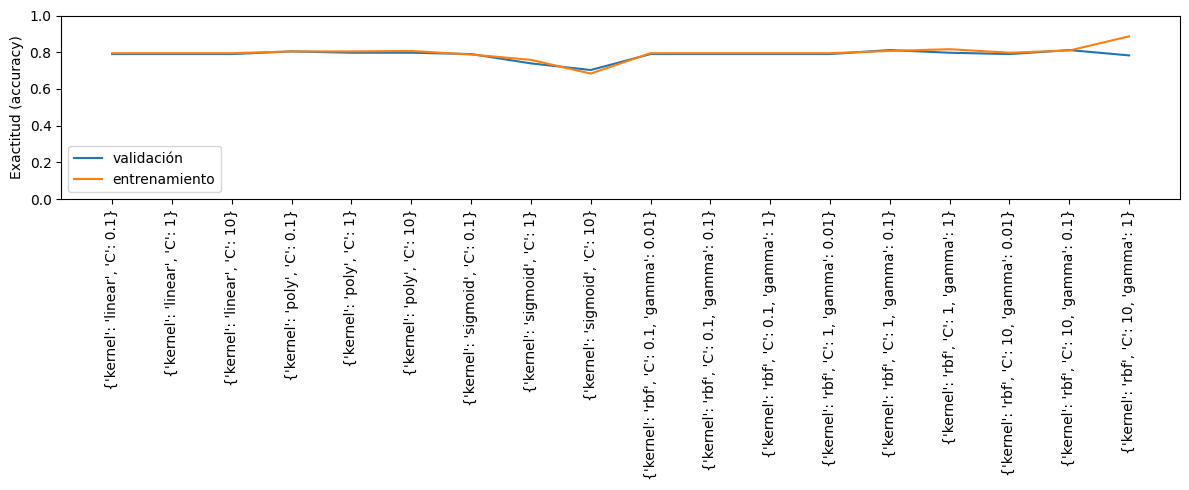

In [7]:
# Búsqueda pequeña y explícita sobre la misma validación
configurations = [
    {'kernel': kernel, 'C': c}
    for kernel in ['linear', 'poly', 'sigmoid'] for c in [0.1, 1, 10]
] + [
    {'kernel': 'rbf', 'C': c, 'gamma': gamma}
    for c in [0.1, 1, 10] for gamma in [0.01, 0.1, 1]
]
results = []
for params in configurations:
    modelo = SVC(**params)
    modelo.fit(X_train_scaled, y_train)
    results.append({
        'params': params,
        'accuracy_train': accuracy_score(y_train, modelo.predict(X_train_scaled)),
        'accuracy_val': accuracy_score(y_val, modelo.predict(X_val_scaled))
    })

# En caso de empate se conserva la primera configuración evaluada
best_result = max(results, key=lambda row: row['accuracy_val'])
best_params = best_result['params'].copy()
display(pd.DataFrame(results))
print("Configuración seleccionada en validación:", best_params)
plt.figure(figsize=(12, 5))
plt.plot(range(len(results)), [r['accuracy_val'] for r in results], label="validación")
plt.plot(range(len(results)), [r['accuracy_train'] for r in results], label="entrenamiento")
plt.xticks(range(len(results)), [str(r['params']) for r in results], rotation=90)
plt.ylabel("Exactitud (accuracy)")
plt.ylim(0, 1)
plt.tight_layout()
plt.legend()
plt.show()


### Modelo SVM
Generamos el modelo con el kernel seleccionado y evaluamos una sola vez en prueba.

In [8]:
# Reajustar con entrenamiento y validación tras fijar la configuración
scaler_final = StandardScaler()
X_trainval_scaled = scaler_final.fit_transform(X_trainval)
X_test_scaled = scaler_final.transform(X_test)
modelo = SVC(**best_params)
modelo.fit(X_trainval_scaled, y_trainval)

# Evaluación final: no usar estos resultados para volver a ajustar
y_pred = modelo.predict(X_test_scaled)
print("Exactitud final (accuracy):", round(accuracy_score(y_test, y_pred), 2))
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred))
print("Reporte de clasificación (precision, recall y F1 por clase):")
print(classification_report(y_test, y_pred, zero_division=0))


Exactitud final (accuracy): 0.81
Matriz de confusión:
[[  3  26]
 [  0 110]]
Reporte de clasificación (precision, recall y F1 por clase):
              precision    recall  f1-score   support

           0       1.00      0.10      0.19        29
           1       0.81      1.00      0.89       110

    accuracy                           0.81       139
   macro avg       0.90      0.55      0.54       139
weighted avg       0.85      0.81      0.75       139



### Matriz de confusión
Los valores de la diagonal son las clasificaciones correctas.

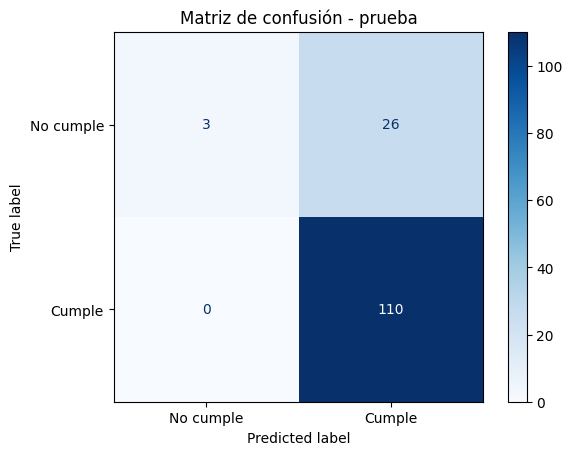

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No cumple", "Cumple"], cmap="Blues")
plt.title("Matriz de confusión - prueba")
plt.show()

### Conclusión
El modelo intenta predecir si un equipo de costura cumple su meta de productividad. La clase que cumple es mayoritaria; por eso, además de la exactitud, es importante revisar el recall y el F1 de la clase que no cumple. Las regiones de decisión usan dos variables y no representan exactamente el modelo final de cuatro variables.